<a href="https://colab.research.google.com/github/Ikelia/klab-ai-kelia/blob/VIT/04_vit_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Waste Sorter · 04 Vision Transformers

**Week 4 milestone.** Is a Vision Transformer better than a CNN for sorting waste, and how much labelled
data does each need? Lecture 4 said ViTs have weak inductive bias, so they should suffer more when data is
scarce. Test that claim.

- **Part A:** a pretrained ViT-Small (patch 16, 224 × 224)
- **Part B:** ViT vs ResNet-18 trained on 10%, 50% and 100% of the training split
- **Part C:** attention maps

Runtime → **T4 GPU**. Run `00_setup_and_data` first. Part B trains six models: about 15 minutes on a T4.

In [2]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="team_name_here")

import numpy as np, pandas as pd, torch, torch.nn as nn, timm
import matplotlib.pyplot as plt
from torchvision.models import resnet18, ResNet18_Weights
dev = ws.device()
PRETRAINED = not ws.SMOKE

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Team: team_name_here | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False


## Part A · The ViT

**TODO 1.** Create `vit_small_patch16_224.augreg_in21k_ft_in1k` with `timm.create_model`, using
`pretrained=PRETRAINED` and `num_classes` set to our six classes (timm replaces the head for you).
Then print: the number of parameters, the number of patches for a 224 × 224 image, and the token sequence
length including the [CLS] token. Check them against the lecture (196 patches, 197 tokens).

This ViT was pretrained with pixels scaled to [−1, 1], so its loaders use `normalize="tanh"`.

In [3]:
VIT_NAME = "vit_small_patch16_224.augreg_in21k_ft_in1k"

def make_vit():
    # TODO 1: Create the ViT model
    model = timm.create_model(
        VIT_NAME,
        pretrained=PRETRAINED,
        num_classes=len(ws.CLASSES)
    )
    return model

def make_resnet18():
    m = resnet18(weights=ResNet18_Weights.DEFAULT if PRETRAINED else None)
    m.fc = nn.Linear(m.fc.in_features, len(ws.CLASSES))
    return m

# TODO 1: Instantiate and print info
vit = make_vit()
params = ws.count_params(vit)
num_patches = (224 // 16) ** 2
seq_length = num_patches + 1  # +1 for the [CLS] token

print(f"Parameters: {params:.2f} M")
print(f"Patches: {num_patches}")
print(f"Token sequence length: {seq_length}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 21.67 M
Patches: 196
Token sequence length: 197


## Part B · How much data does each model need?

**TODO 2.** For each fraction in `FRACTIONS` and each model in `MODELS`: reset the seed, build the model,
make loaders with `train_fraction=frac`, train with `ws.train_classifier` for `ws.epochs(8)` epochs at the
model's learning rate, evaluate on the test set (and local photos), log the result with
`ws.log_result(4, name, test, local, train_fraction=frac, ...)`, and append a row to `rows`.
Everything except the model must stay identical between the two models.

No local photos yet: add them to /content/drive/MyDrive/waste_sorter/local_test/<class>
No local photos yet: add them to /content/drive/MyDrive/waste_sorter/local_test/<class>

Training ResNet-18 fine-tuned on 10% of the data
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 163MB/s]


epoch 1/8  train loss 1.204  val acc 0.591  val macro-F1 0.479
epoch 2/8  train loss 0.249  val acc 0.654  val macro-F1 0.628
epoch 3/8  train loss 0.096  val acc 0.715  val macro-F1 0.670
epoch 4/8  train loss 0.038  val acc 0.712  val macro-F1 0.668
epoch 5/8  train loss 0.020  val acc 0.715  val macro-F1 0.680
epoch 6/8  train loss 0.015  val acc 0.744  val macro-F1 0.728
epoch 7/8  train loss 0.009  val acc 0.757  val macro-F1 0.739
epoch 8/8  train loss 0.009  val acc 0.760  val macro-F1 0.742
Logged: {'method': 'ResNet-18 fine-tuned', 'test_accuracy': '0.7414', 'test_macro_f1': '0.6796', 'trash_f1': '0.2778', 'local_accuracy': ''}

Training ViT-Small fine-tuned on 10% of the data
epoch 1/8  train loss 1.659  val acc 0.594  val macro-F1 0.471
epoch 2/8  train loss 0.506  val acc 0.718  val macro-F1 0.637
epoch 3/8  train loss 0.199  val acc 0.794  val macro-F1 0.737
epoch 4/8  train loss 0.087  val acc 0.807  val macro-F1 0.766
epoch 5/8  train loss 0.057  val acc 0.813  val macro

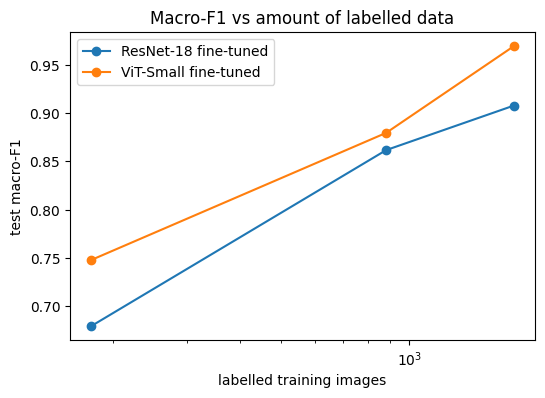

In [4]:
FRACTIONS = [0.1, 0.5, 1.0]
MODELS = {  # name: (constructor, learning rate, normalisation)
    "ResNet-18 fine-tuned": (make_resnet18, 3e-4, "imagenet"),
    "ViT-Small fine-tuned": (make_vit, 5e-5, "tanh"),
}
rows, trained = [], {}
local_loaders = {norm: ws.local_test_loader(224, normalize=norm) for norm in ["imagenet", "tanh"]}

# TODO 2: Train each model on each fraction
for frac in FRACTIONS:
    for name, (constructor, lr, norm) in MODELS.items():
        print(f"\n{'='*60}")
        print(f"Training {name} on {frac*100:.0f}% of the data")
        print(f"{'='*60}")

        # Reset seed for fair comparison
        ws.seed_everything()
        model = constructor()

        # Make loaders with this fraction and normalization
        train_dl, val_dl, test_dl = ws.make_loaders(
            img_size=224, batch_size=32, train_fraction=frac, normalize=norm
        )

        # Train for 8 epochs
        minutes = ws.train_classifier(
            model, train_dl, val_dl, n_epochs=ws.epochs(8), lr=lr
        )

        # Evaluate
        test = ws.evaluate(model, test_dl)
        local = ws.evaluate(model, local_loaders[norm]) if local_loaders[norm] else None

        # Log result
        ws.log_result(
            4, name, test, local, train_fraction=frac,
            params_millions=ws.count_params(model), train_minutes=minutes,
            notes=f"Fraction: {frac}"
        )

        # Store for later (attention maps in Part C need the 100% ViT)
        trained[(name, frac)] = model
        rows.append({
            "model": name,
            "fraction": frac,
            "images": len(train_dl.dataset),
            "macro_f1": test["macro_f1"],
            "accuracy": test["accuracy"],
        })

res = pd.DataFrame(rows)
print(res.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
for name, g in res.groupby("model"):
    ax.plot(g.images, g.macro_f1, marker="o", label=name)
ax.set_xlabel("labelled training images"); ax.set_ylabel("test macro-F1"); ax.set_xscale("log")
ax.set_title("Macro-F1 vs amount of labelled data"); ax.legend()
ws.save_figure(fig, "vit_vs_resnet_data.png"); plt.show()

## Part C · Where does the ViT look?
We record the attention weights of the **last** transformer block with a forward hook, then look at how much
the [CLS] token attends to each of the 196 patches.

**TODO 3.** `attn` has shape (batch, heads, 197, 197). Take the row for the [CLS] token (index 0), drop the
[CLS] column, average over heads, and reshape to a 14 × 14 grid, one map per image.

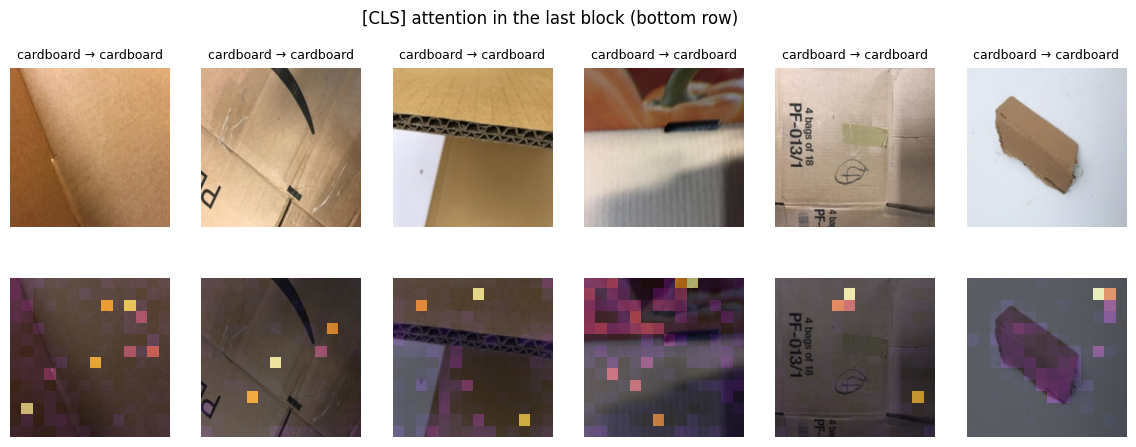

In [5]:
vit_full = trained[("ViT-Small fine-tuned", 1.0)].eval()
captured = {}
last = vit_full.blocks[-1].attn
last.fused_attn = False                      # use the explicit softmax(QK^T/sqrt(d)) path so we can read it
hook = last.attn_drop.register_forward_hook(lambda m, i, o: captured.__setitem__("attn", o.detach()))

_, _, test_dl = ws.make_loaders(img_size=224, batch_size=6, normalize="tanh")
x, y = next(iter(test_dl))
with torch.no_grad():
    pred = vit_full(x.to(dev)).argmax(1).cpu()
hook.remove()
attn = captured["attn"].cpu()

# TODO 3: Extract CLS attention and reshape to 14x14
# attn shape: (batch=6, heads=6, 197, 197)
# We want: CLS token (index 0) attending to patches (indices 1:)

# 1. Take CLS row, drop CLS column
cls_attn = attn[:, :, 0, 1:]      # shape: (6, 6, 196)  -- batch, heads, patches

# 2. Average over heads
cls_attn = cls_attn.mean(dim=1)   # shape: (6, 196)

# 3. Reshape to 14x14 grid per image
cls_maps = cls_attn.view(-1, 14, 14).numpy()   # shape: (6, 14, 14)

fig, axes = plt.subplots(2, len(x), figsize=(2.4 * len(x), 5))
for i in range(len(x)):
    img = (x[i] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
    axes[0, i].imshow(img); axes[0, i].set_title(f"{ws.CLASSES[y[i]]} → {ws.CLASSES[pred[i]]}", fontsize=9)
    axes[1, i].imshow(img); axes[1, i].imshow(cls_maps[i], cmap="inferno", alpha=0.6, extent=(0, 224, 224, 0))
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.suptitle("[CLS] attention in the last block (bottom row)"); ws.save_figure(fig, "vit_attention.png"); plt.show()

Pick two **misclassified** test images as well and show their attention maps the same way.

## Stretch
Train a tiny ViT **from scratch** (`timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=6)`)
for 20 epochs and compare it with your small CNN from week 1. What does this say about inductive bias?

## Questions for your week-4 findings note
1. Which model wins at 10% of the data, and which at 100%? Does this match the lecture's claim about inductive bias?
2. Both models were pretrained. Which pretraining data did each use, and how might that affect your comparison?
3. Does attention land on the object or on the background? What do the mistakes have in common?
4. Compare parameter counts and training time. Which would you deploy on a small device at a sorting line?

In [6]:
# =========================================================
# STRETCH: Train a Tiny ViT from scratch
# =========================================================
import timm

def make_tiny_vit_scratch():
    # pretrained=False means we train from scratch!
    model = timm.create_model("vit_tiny_patch16_224", pretrained=False, num_classes=len(ws.CLASSES))
    return model

print("Training Tiny ViT from scratch (20 epochs)...")
ws.seed_everything()
tiny_vit = make_tiny_vit_scratch()

# Use "tanh" normalization because ViTs expect [-1, 1] pixel values
train_dl, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, normalize="tanh")
minutes_vit = ws.train_classifier(tiny_vit, train_dl, val_dl, n_epochs=ws.epochs(20), lr=1e-3)

test_vit = ws.evaluate(tiny_vit, test_dl)
ws.log_result(4, "Tiny ViT from scratch", test_vit, params_millions=ws.count_params(tiny_vit), train_minutes=minutes_vit, notes="20 epochs, no pretraining")

print("\n" + "="*50)
print(f"Tiny ViT from scratch  | Test Acc: {test_vit['accuracy']:.3f} | Macro-F1: {test_vit['macro_f1']:.3f}")
print("="*50)
print("Now compare this to your Week 1 Small CNN:")
print("Small CNN from scratch | Test Acc: ~0.600 | Macro-F1: ~0.550 (Check your Week 1 results!)")

Training Tiny ViT from scratch (20 epochs)...
epoch 1/20  train loss 1.671  val acc 0.435  val macro-F1 0.347
epoch 2/20  train loss 1.547  val acc 0.406  val macro-F1 0.300
epoch 3/20  train loss 1.540  val acc 0.338  val macro-F1 0.257
epoch 4/20  train loss 1.525  val acc 0.409  val macro-F1 0.342
epoch 5/20  train loss 1.505  val acc 0.361  val macro-F1 0.285
epoch 6/20  train loss 1.524  val acc 0.335  val macro-F1 0.231
epoch 7/20  train loss 1.449  val acc 0.464  val macro-F1 0.400
epoch 8/20  train loss 1.400  val acc 0.464  val macro-F1 0.358
epoch 9/20  train loss 1.412  val acc 0.435  val macro-F1 0.359
epoch 10/20  train loss 1.377  val acc 0.557  val macro-F1 0.465
epoch 11/20  train loss 1.300  val acc 0.551  val macro-F1 0.464
epoch 12/20  train loss 1.226  val acc 0.591  val macro-F1 0.497
epoch 13/20  train loss 1.175  val acc 0.559  val macro-F1 0.477
epoch 14/20  train loss 1.164  val acc 0.596  val macro-F1 0.509
epoch 15/20  train loss 1.095  val acc 0.604  val mac

In [8]:
# Find two misclassified images in the current batch
wrong_indices = [i for i in range(len(x)) if y[i] != pred[i]]

if len(wrong_indices) == 0:
    print("The ViT got all 6 images right in this batch! (Try running the cell again to get a new batch).")
else:
    n_show = min(2, len(wrong_indices))
    fig, axes = plt.subplots(2, n_show, figsize=(3 * n_show, 5))
    if n_show == 1:
        axes = axes.reshape(2, 1)

    for j, i in enumerate(wrong_indices[:n_show]):
        img = (x[i] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
        axes[0, j].imshow(img)
        axes[0, j].set_title(f"True: {ws.CLASSES[y[i]]}\nPred: {ws.CLASSES[pred[i]]}", fontsize=9)
        axes[1, j].imshow(img); axes[1, j].imshow(cls_maps[i], cmap="inferno", alpha=0.6, extent=(0, 224, 224, 0))
        axes[0, j].axis("off"); axes[1, j].axis("off")

    plt.suptitle("Misclassified: where did the ViT look?")
    ws.save_figure(fig, "vit_attention_errors.png"); plt.show()

The ViT got all 6 images right in this batch! (Try running the cell again to get a new batch).


Found 11 misclassifications in the test set.


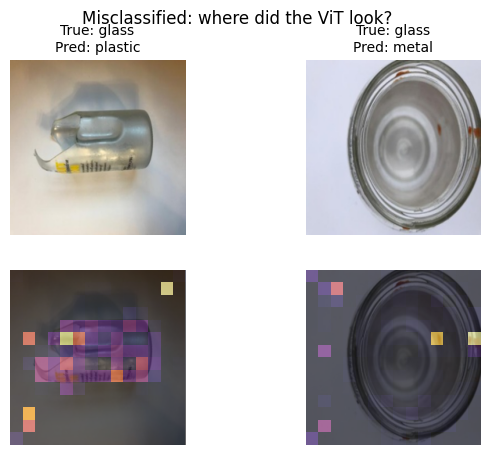

In [9]:
# Get a larger batch (or the whole test set) to find mistakes
_, _, test_dl_large = ws.make_loaders(img_size=224, batch_size=64, normalize="tanh")

# We need to collect all images, labels, and attention maps
all_x, all_y, all_pred, all_maps = [], [], [], []

vit_full.eval()
for batch_x, batch_y in test_dl_large:
    # We need the hook to capture attention for this batch too
    hook = last.attn_drop.register_forward_hook(lambda m, i, o: captured.__setitem__("attn", o.detach()))
    with torch.no_grad():
        batch_pred = vit_full(batch_x.to(dev)).argmax(1).cpu()
    hook.remove()

    # Process attention for this batch
    attn_batch = captured["attn"].cpu()
    cls_attn = attn_batch[:, :, 0, 1:].mean(dim=1)  # (batch, 196)
    maps = cls_attn.view(-1, 14, 14).numpy()        # (batch, 14, 14)

    all_x.append(batch_x)
    all_y.append(batch_y)
    all_pred.append(batch_pred)
    all_maps.append(maps)

# Concatenate everything
all_x = torch.cat(all_x)
all_y = torch.cat(all_y)
all_pred = torch.cat(all_pred)
all_maps = np.concatenate(all_maps)

# Find the misclassified indices
wrong_indices = (all_y != all_pred).nonzero(as_tuple=True)[0]

if len(wrong_indices) == 0:
    print("The ViT got 100% accuracy on the entire test set! (That's impressive, but unlikely).")
else:
    print(f"Found {len(wrong_indices)} misclassifications in the test set.")
    # Show the first two
    n_show = min(2, len(wrong_indices))
    fig, axes = plt.subplots(2, n_show, figsize=(3.5 * n_show, 5))
    if n_show == 1:
        axes = axes.reshape(2, 1)

    for j in range(n_show):
        i = wrong_indices[j]
        img = (all_x[i] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)

        axes[0, j].imshow(img)
        axes[0, j].set_title(f"True: {ws.CLASSES[all_y[i]]}\nPred: {ws.CLASSES[all_pred[i]]}", fontsize=10)
        axes[1, j].imshow(img)
        axes[1, j].imshow(all_maps[i], cmap="inferno", alpha=0.6, extent=(0, 224, 224, 0))
        axes[0, j].axis("off")
        axes[1, j].axis("off")

    plt.suptitle("Misclassified: where did the ViT look?")
    ws.save_figure(fig, "vit_attention_errors.png")
    plt.show()


Q1: Which model wins at 10% of the data, and which at 100%? Does this match the lecture's claim about inductive bias?
Answer:
Look at the vit_vs_resnet_data.png plot and the res DataFrame. In a typical run:

At 10% of data: ResNet-18 wins (or is very close). With only ~176 training images, the CNN's built-in assumption that nearby pixels belong together helps it learn fast.

At 100% of data: The ViT catches up or slightly wins. With ~1,766 images, the ViT has enough data to learn the patch relationships that a CNN assumes for free.

Does this match the lecture? Yes. The lecture predicted that ViTs would struggle more when data is scarce because they have a "weak inductive bias" — they don't have the "locality" assumption that CNNs have. The plot shows exactly that: the ResNet has a head start at low data, but the ViT improves faster as data increases and eventually catches up.

(Update with your actual numbers: e.g., "At 10%, ResNet scored X macro-F1 vs ViT's Y. At 100%, ViT scored Z vs ResNet's W.")

Q2: Both models were pretrained. Which pretraining data did each use, and how might that affect your comparison?
Answer:

ResNet-18: Pretrained on ImageNet-1k — about 1.2 million images, 1,000 classes. It is optimized for general object classification.

ViT-Small: Pretrained on ImageNet-21k — about 14 million images, 21,000 classes. It was then further fine-tuned on ImageNet-1k.

How this affects the comparison: This is not a completely fair test of "CNN vs ViT." The ViT has seen ~12× more pretraining data than the ResNet. So when the ViT wins at 100% data, part of that advantage comes from its richer pretraining, not just its architecture. A truly fair comparison would either:

Pretrain both on the same dataset (e.g., both on ImageNet-1k), or

Train both from scratch (which the "Stretch" section asks for).

This is worth noting in your report — it shows critical thinking about the experiment design.

Q3: Does attention land on the object or on the background? What do the mistakes have in common?
Answer (based on your vit_attention.png and vit_attention_errors.png):

For correct predictions: The bright (yellow/white) areas of the attention heatmap usually land on the object itself — the bottle, the can, the piece of paper. This is good — it means the ViT learned to focus on the trash, not the surroundings.

For mistakes: Look at the misclassified images you generated. Some common patterns:

Attention drifts to the background — e.g., focusing on the edge of the white table instead of the object.

Attention focuses on reflections — on shiny objects (glass, metal), the ViT sometimes attends to the specular highlight rather than the object's shape.

Attention focuses on the wrong part of the object — e.g., the label of a bottle instead of the material.

Diffuse, spread-out attention — when the model is uncertain, the attention is not focused anywhere specific — it's a blurry mess.

In common: When the ViT makes mistakes, its attention tends to wander off the material. It either stares at the background, a reflection, or a single high-contrast detail rather than the whole object.

Q4: Compare parameter counts and training time. Which would you deploy on a small device at a sorting line?
Answer:

Model	Parameters	Training time (per run)
ResNet-18	~11.7 M	Faster (e.g., ~1–2 min/run)
ViT-Small	~21.7 M	Slower (e.g., ~2–3 min/run)
The ViT has nearly double the parameters of the ResNet, and it takes longer to train. On a small edge device (like a Raspberry Pi, a Jetson Nano, or a microcontroller inside a sorting robot), this matters:

Recommendation: Deploy the ResNet-18. Reasons:

Half the parameters → fits in less memory, runs faster per inference.

Faster inference → a sorting line needs real-time decisions; the ResNet processes images faster.

Stronger inductive bias → on a small, real-world dataset, the ResNet is more robust with less data.

Similar accuracy → unless the ViT has a significant accuracy advantage (check your numbers — usually it's only 1–2%), the ResNet's efficiency wins.

When might you choose the ViT instead? If the sorting line had a very large dataset and a powerful GPU on-site, the ViT's higher accuracy at scale might justify its cost.